In [1]:
!pip install roboflow ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 1.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 336.8/336.8 kB 30.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 45.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 109.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 6.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.0/96.0 kB 11.1 MB/s eta 0:00:00
  Attempting uninstall: typer
    Found existing installation: typer 0.27.2
    Uninstalling typer-0.27.2:
      Successfully uninstalled typer-0.27.2


In [2]:
from roboflow import Roboflow
from ultralytics import YOLO

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


In [3]:
!pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key="rPwJPT4un0rzgamkfnrr")
project = rf.workspace("vijayalakshmis-workspace-7zfet").project("fruits-fresh-and-rotten-mhcpd")
version = project.version(2)
dataset = version.download("yolov8")


loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to Fruits-Fresh-and-Rotten-2 in yolov8:: 100%|██████████| 65280/65280 [00:09<00:00, 6757.03it/s] 


In [4]:
import os

print(os.listdir(dataset.location))

['train', 'valid', 'data.yaml', 'test', 'README.roboflow.txt']


In [5]:
model = YOLO("yolov8n.pt")

In [6]:
from ultralytics import YOLO

model = YOLO("yolov8n.pt")

results = model.train(
    data=f"{dataset.location}/data.yaml",
    epochs=30,
    imgsz=640,
    batch=16
)

Ultralytics 8.4.173 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Fruits-Fresh-and-Rotten-2/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=None, opset=None, optimize

In [7]:
metrics = model.val()

print("mAP50:", metrics.box.map50)
print("mAP50-95:", metrics.box.map)
print("Precision:", metrics.box.mp)
print("Recall:", metrics.box.mr)


Ultralytics 8.4.173 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 3,006,818 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 929.3±296.2 MB/s, size: 27.9 KB)
val: Scanning /content/Fruits-Fresh-and-Rotten-2/valid/labels.cache... 2040 images, 2 backgrounds, 3 corrupt: 100% ━━━━━━━━━━━━ 2040/2040 570.4Mit/s 0.0s
val: /content/Fruits-Fresh-and-Rotten-2/valid/images/Screen-Shot-2018-06-12-at-9_18_57-PM_png.rf.7270fc750036580f8005abc15da2fe04.jpg: ignoring corrupt image/label: labels mix segment and detection rows
val: /content/Fruits-Fresh-and-Rotten-2/valid/images/rotated_by_15_Screen-Shot-2018-06-08-at-4_59_49-PM_png.rf.677aced481b316ff60b56314f31ad549.jpg: ignoring corrupt image/label: labels mix segment and detection rows
val: /content/Fruits-Fresh-and-Rotten-2/valid/images/rotated_by_30_Screen-Shot-2018-06-12-at-9_46_12-PM_png.rf.1e76caf261289144e51154427449bfd8.jpg: ignoring corrupt image/label: 

In [10]:
import glob

pt_files = glob.glob("/content/**/*.pt", recursive=True)

print(pt_files)

['/content/yolov8n.pt', '/content/weights/yolo26n.pt', '/content/runs/detect/train/weights/best.pt', '/content/runs/detect/train/weights/last.pt']


In [11]:
from google.colab import files

files.download("/content/runs/detect/train/weights/best.pt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

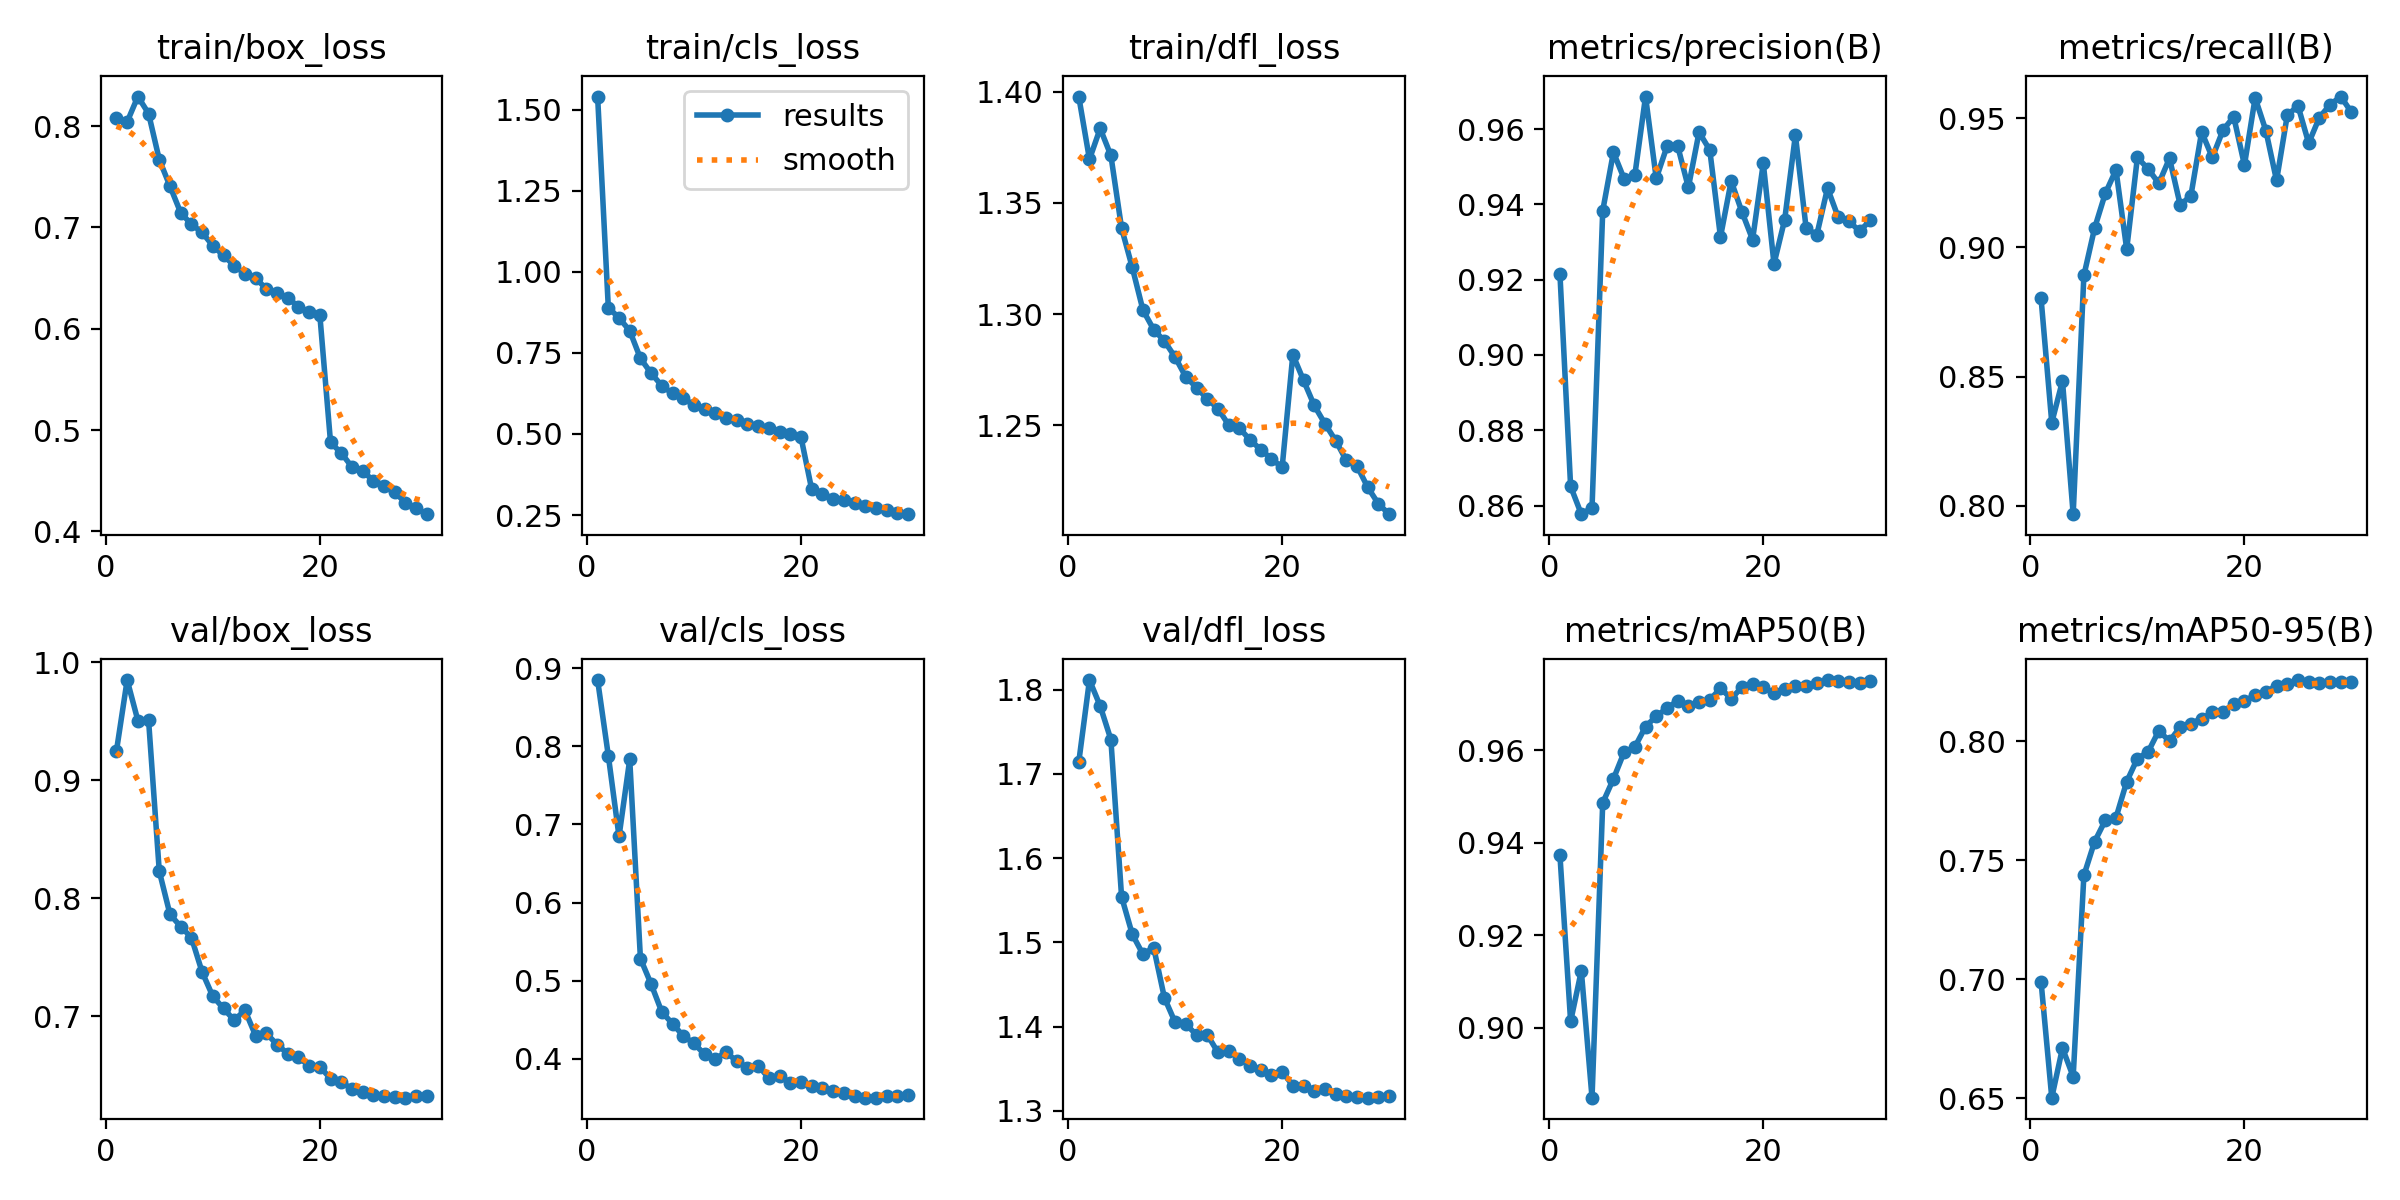

In [12]:
from IPython.display import Image, display

display(Image("/content/runs/detect/train/results.png"))

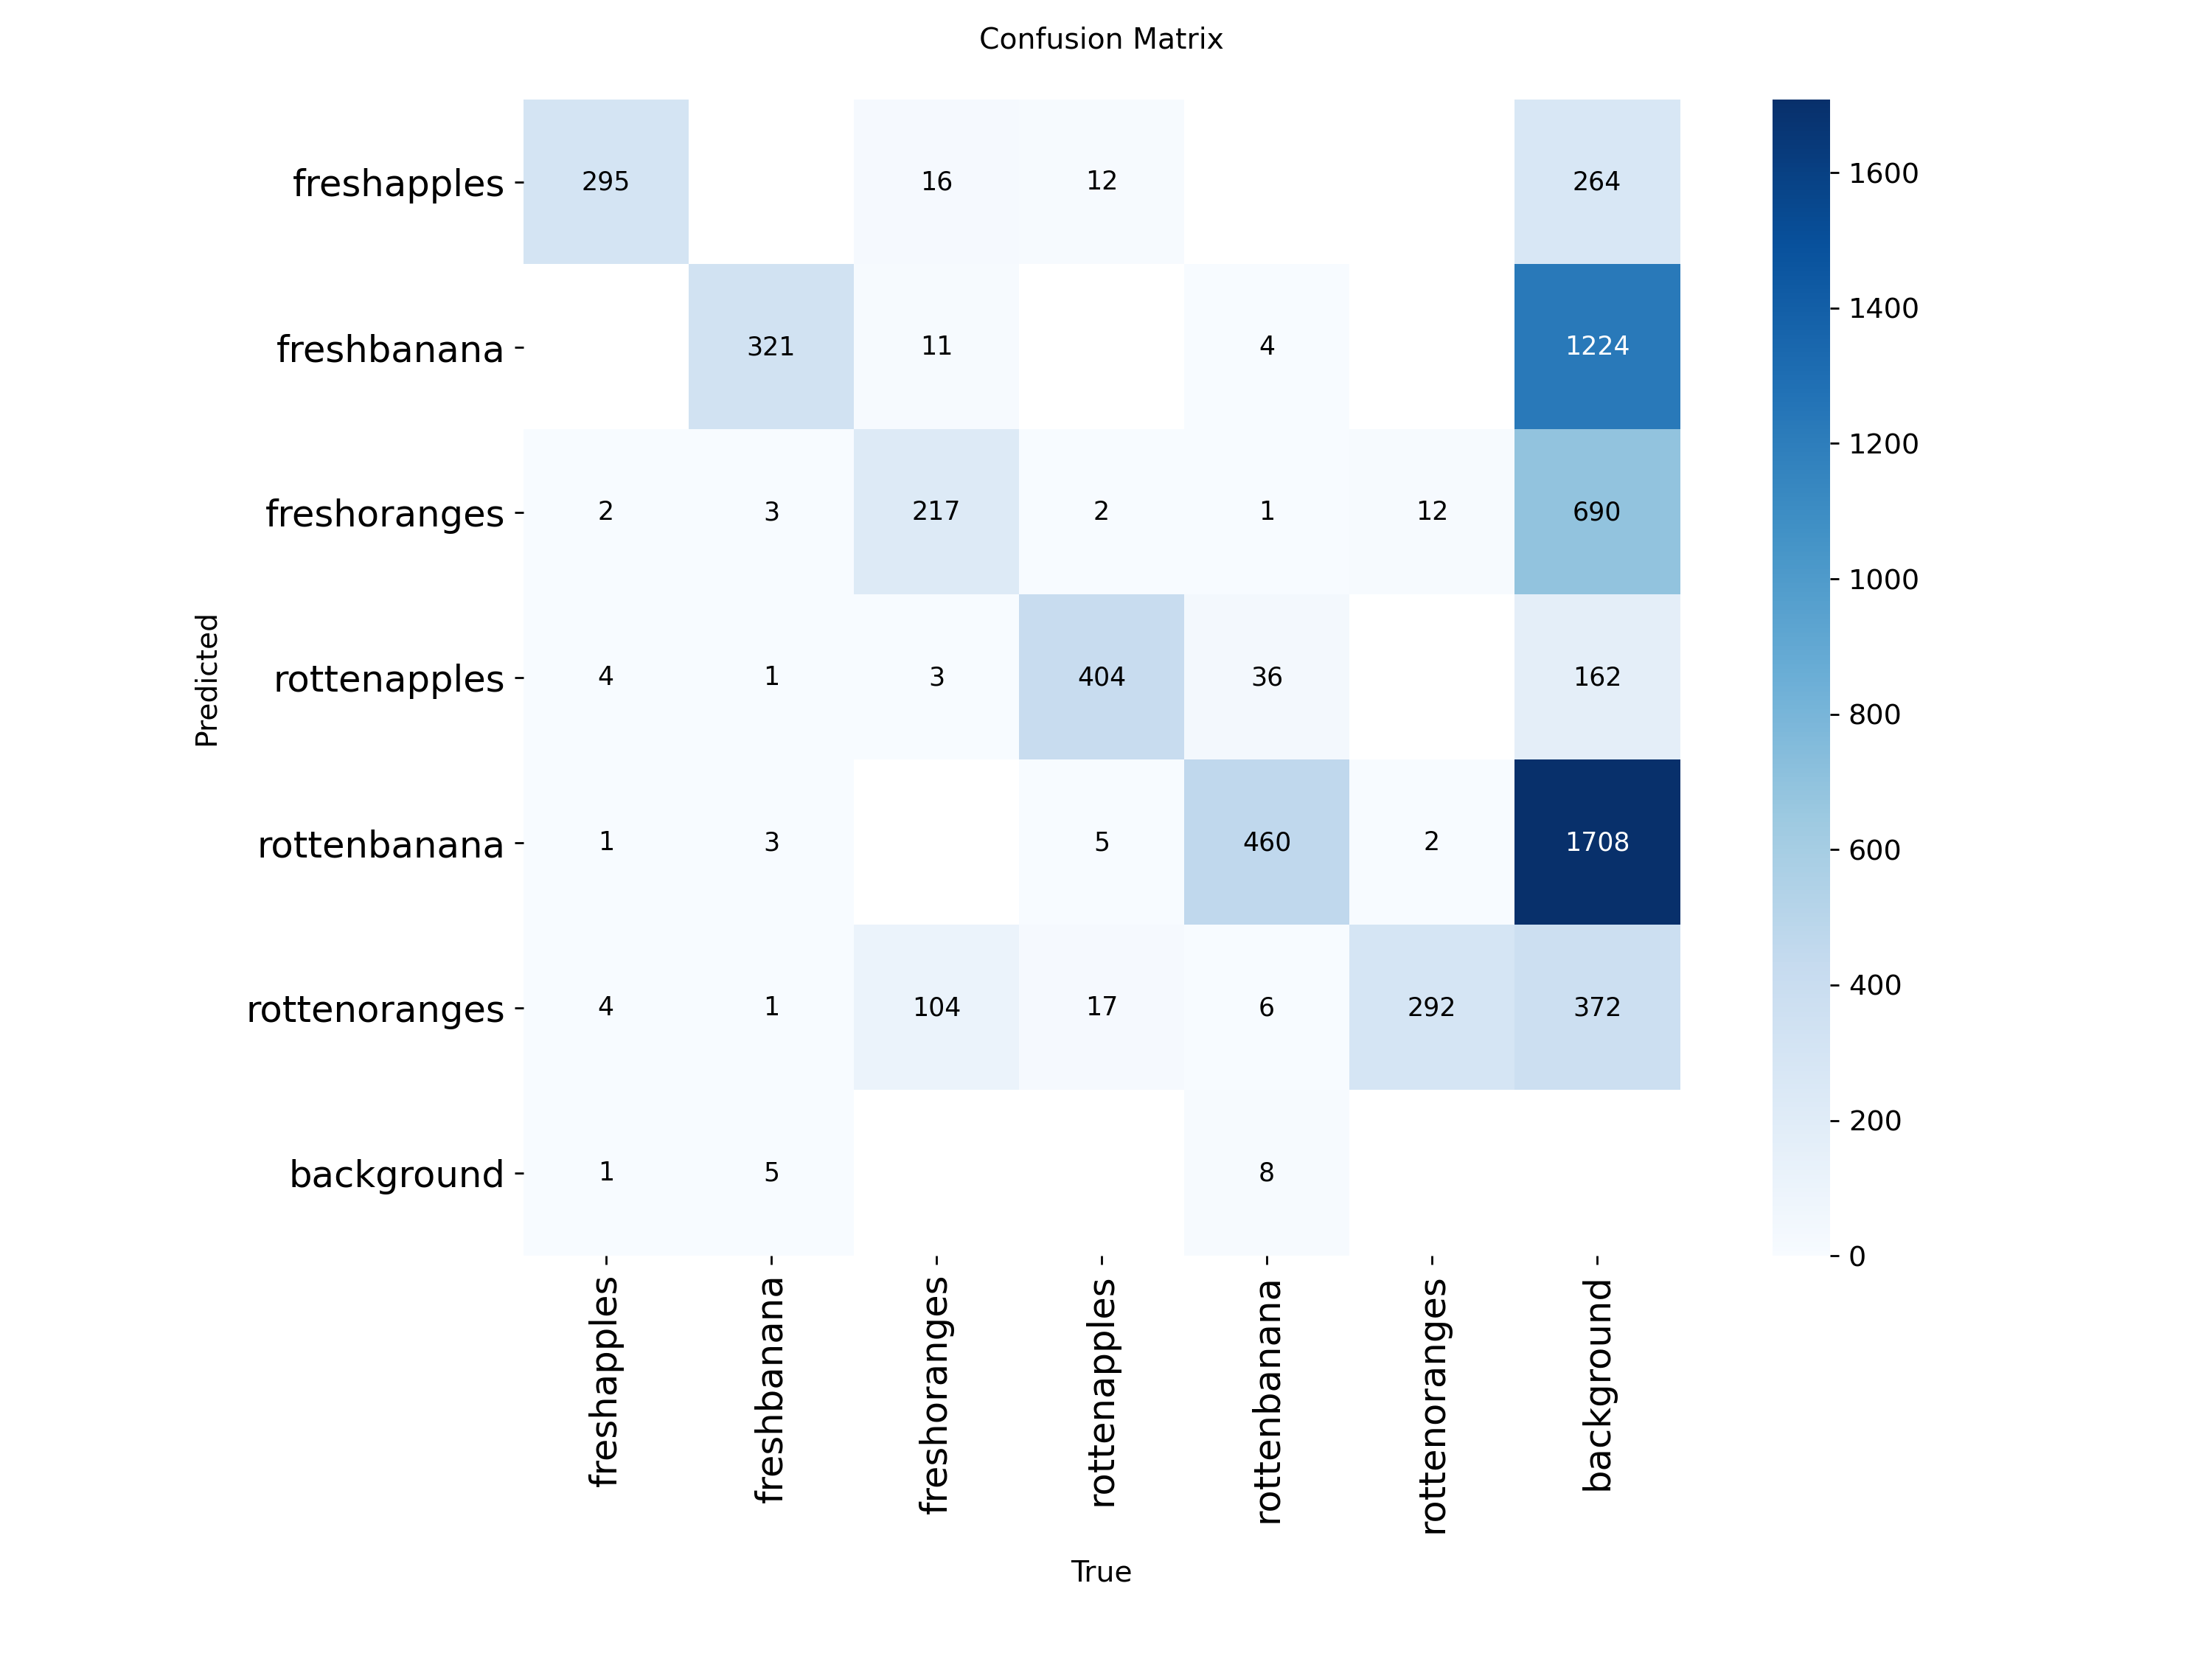

In [13]:
display(Image("/content/runs/detect/train/confusion_matrix.png"))

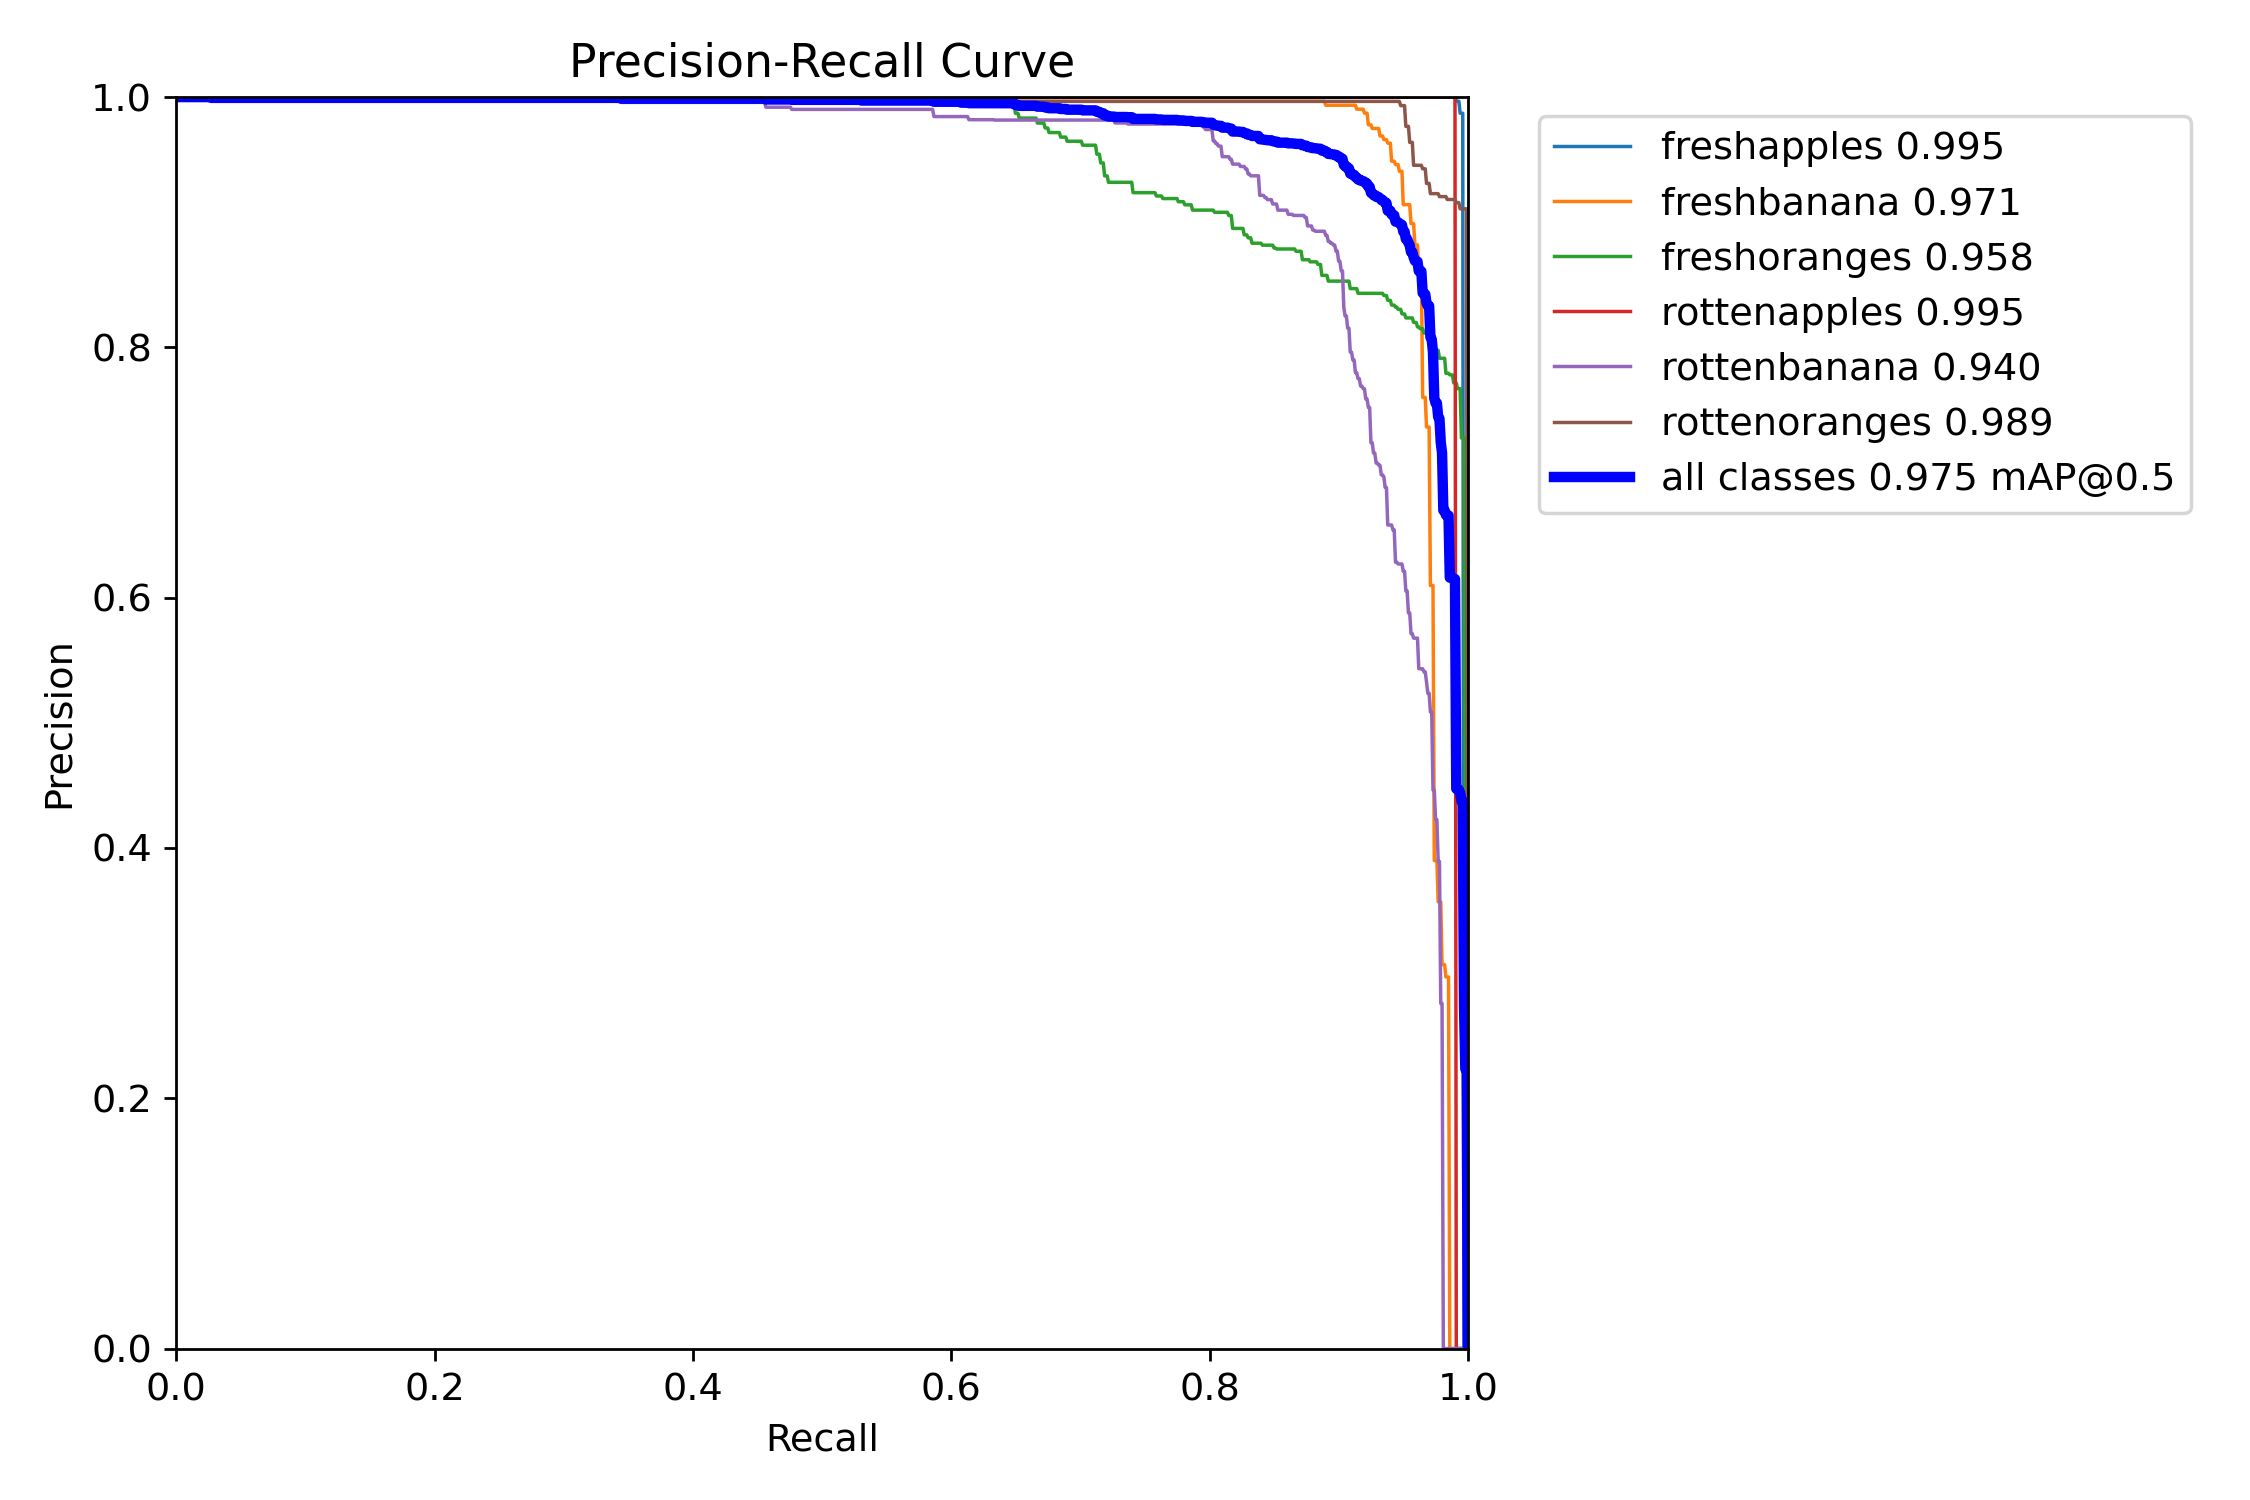

In [14]:
display(Image("/content/runs/detect/train/BoxPR_curve.png"))

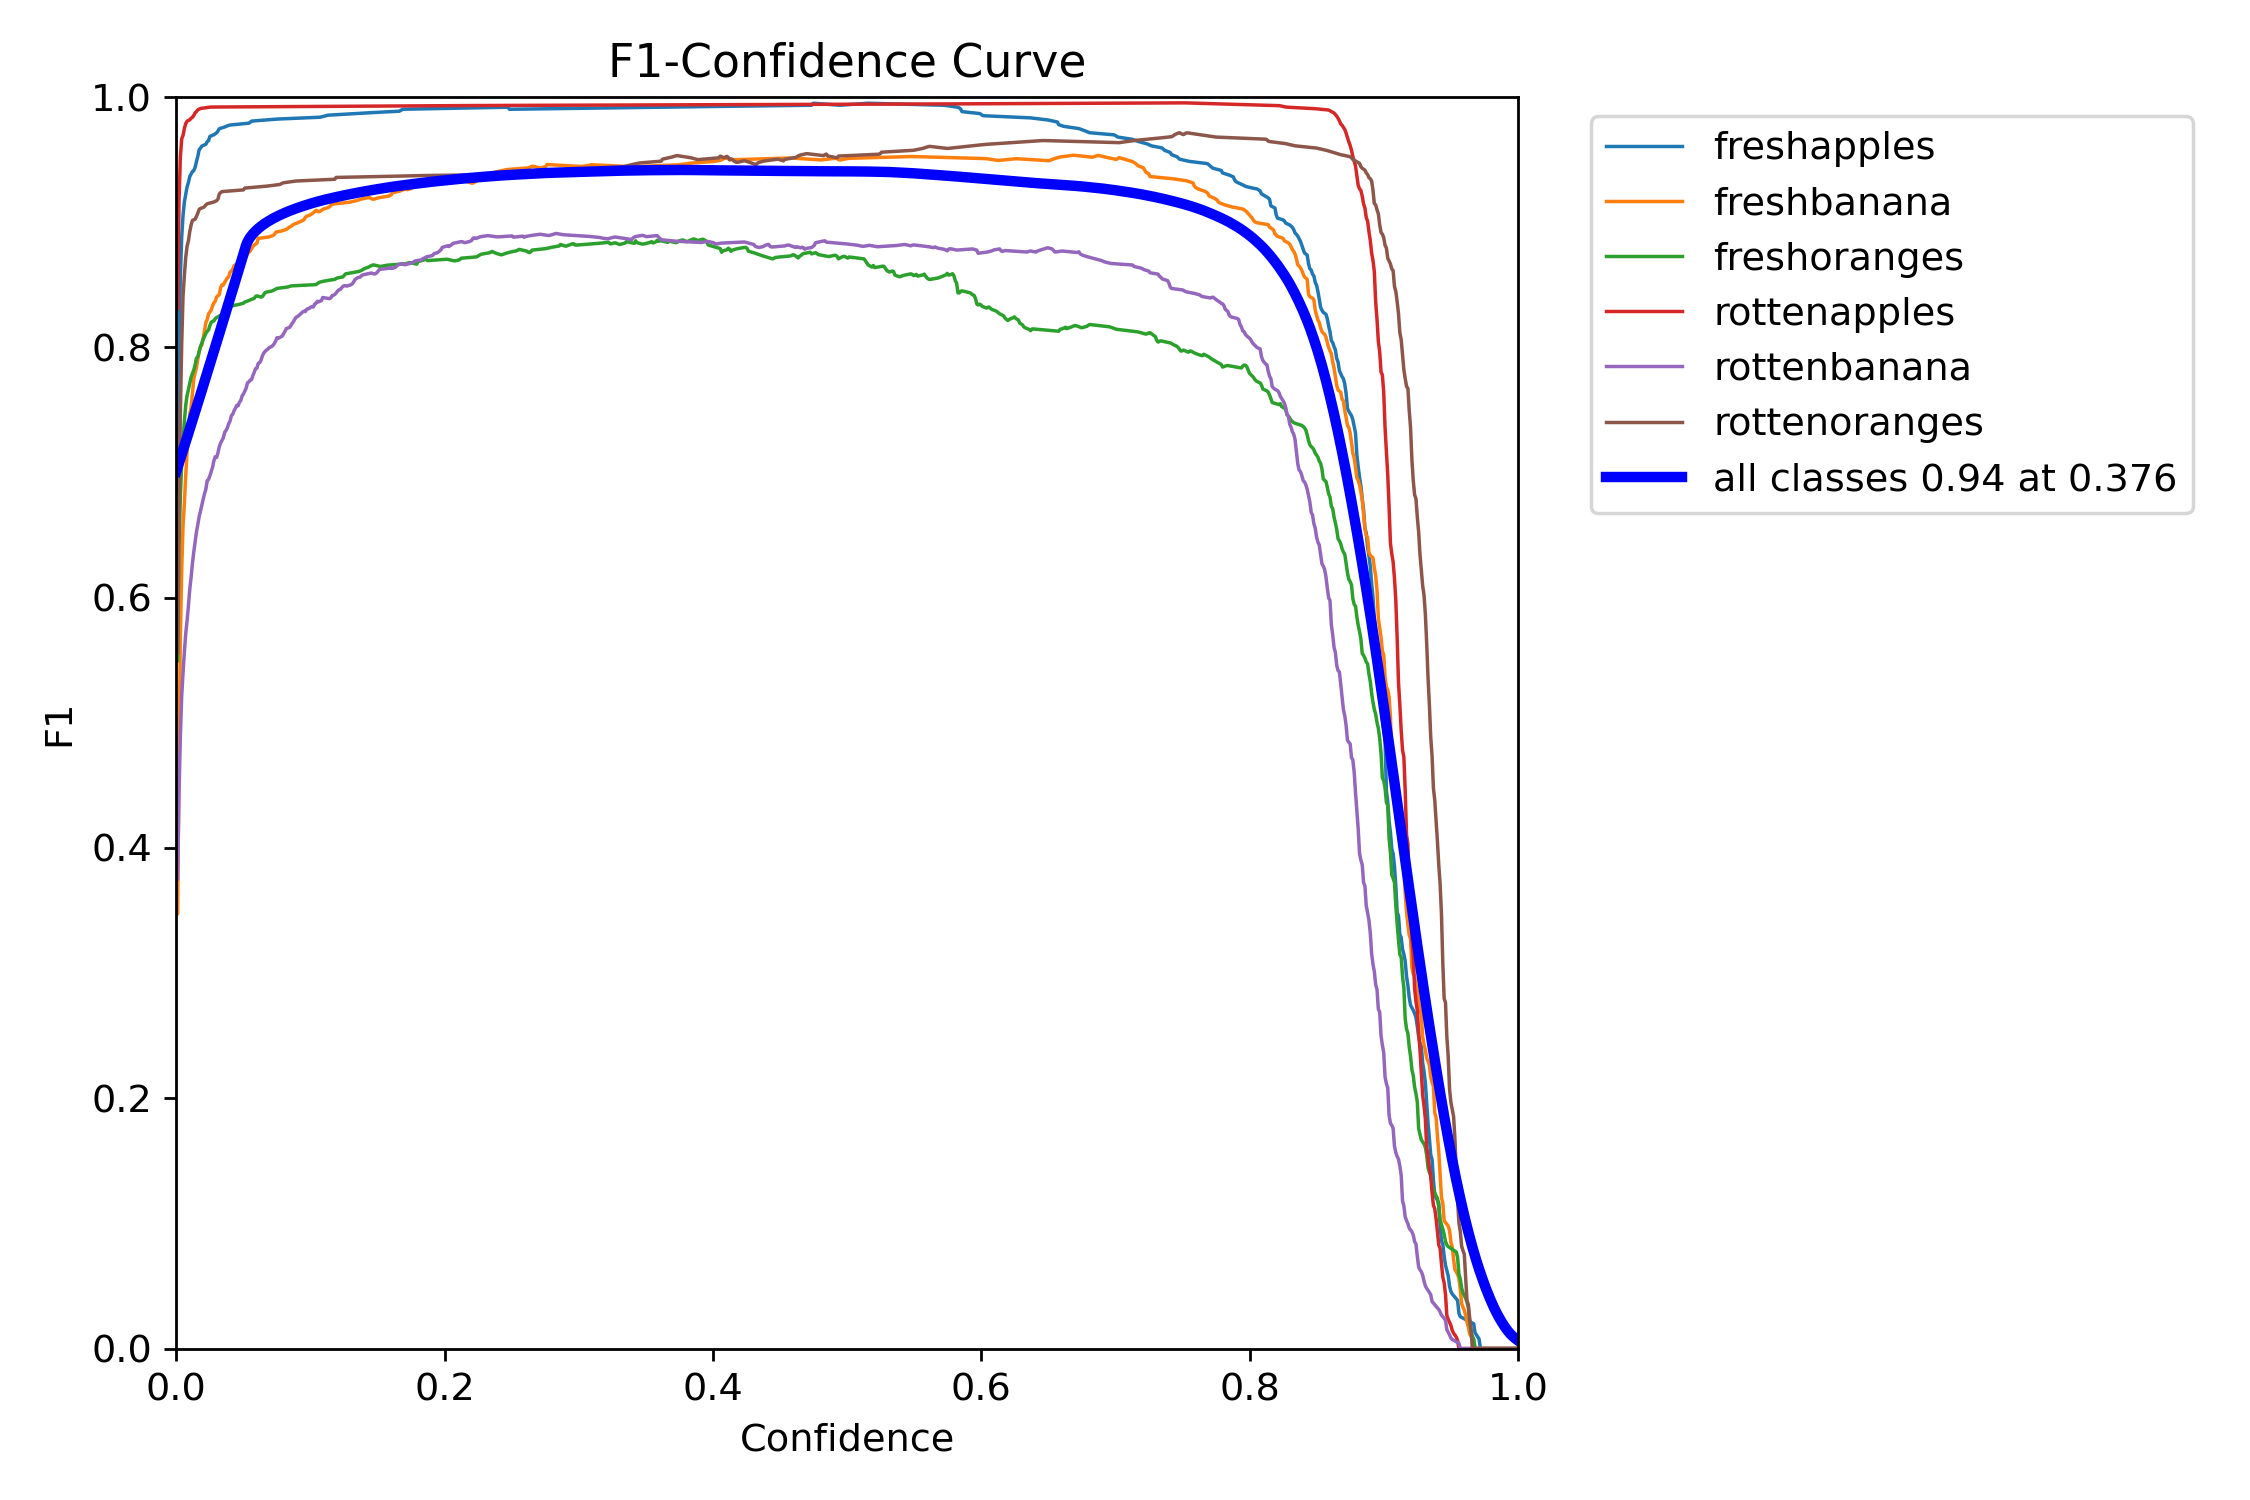

In [15]:
display(Image("/content/runs/detect/train/BoxF1_curve.png"))

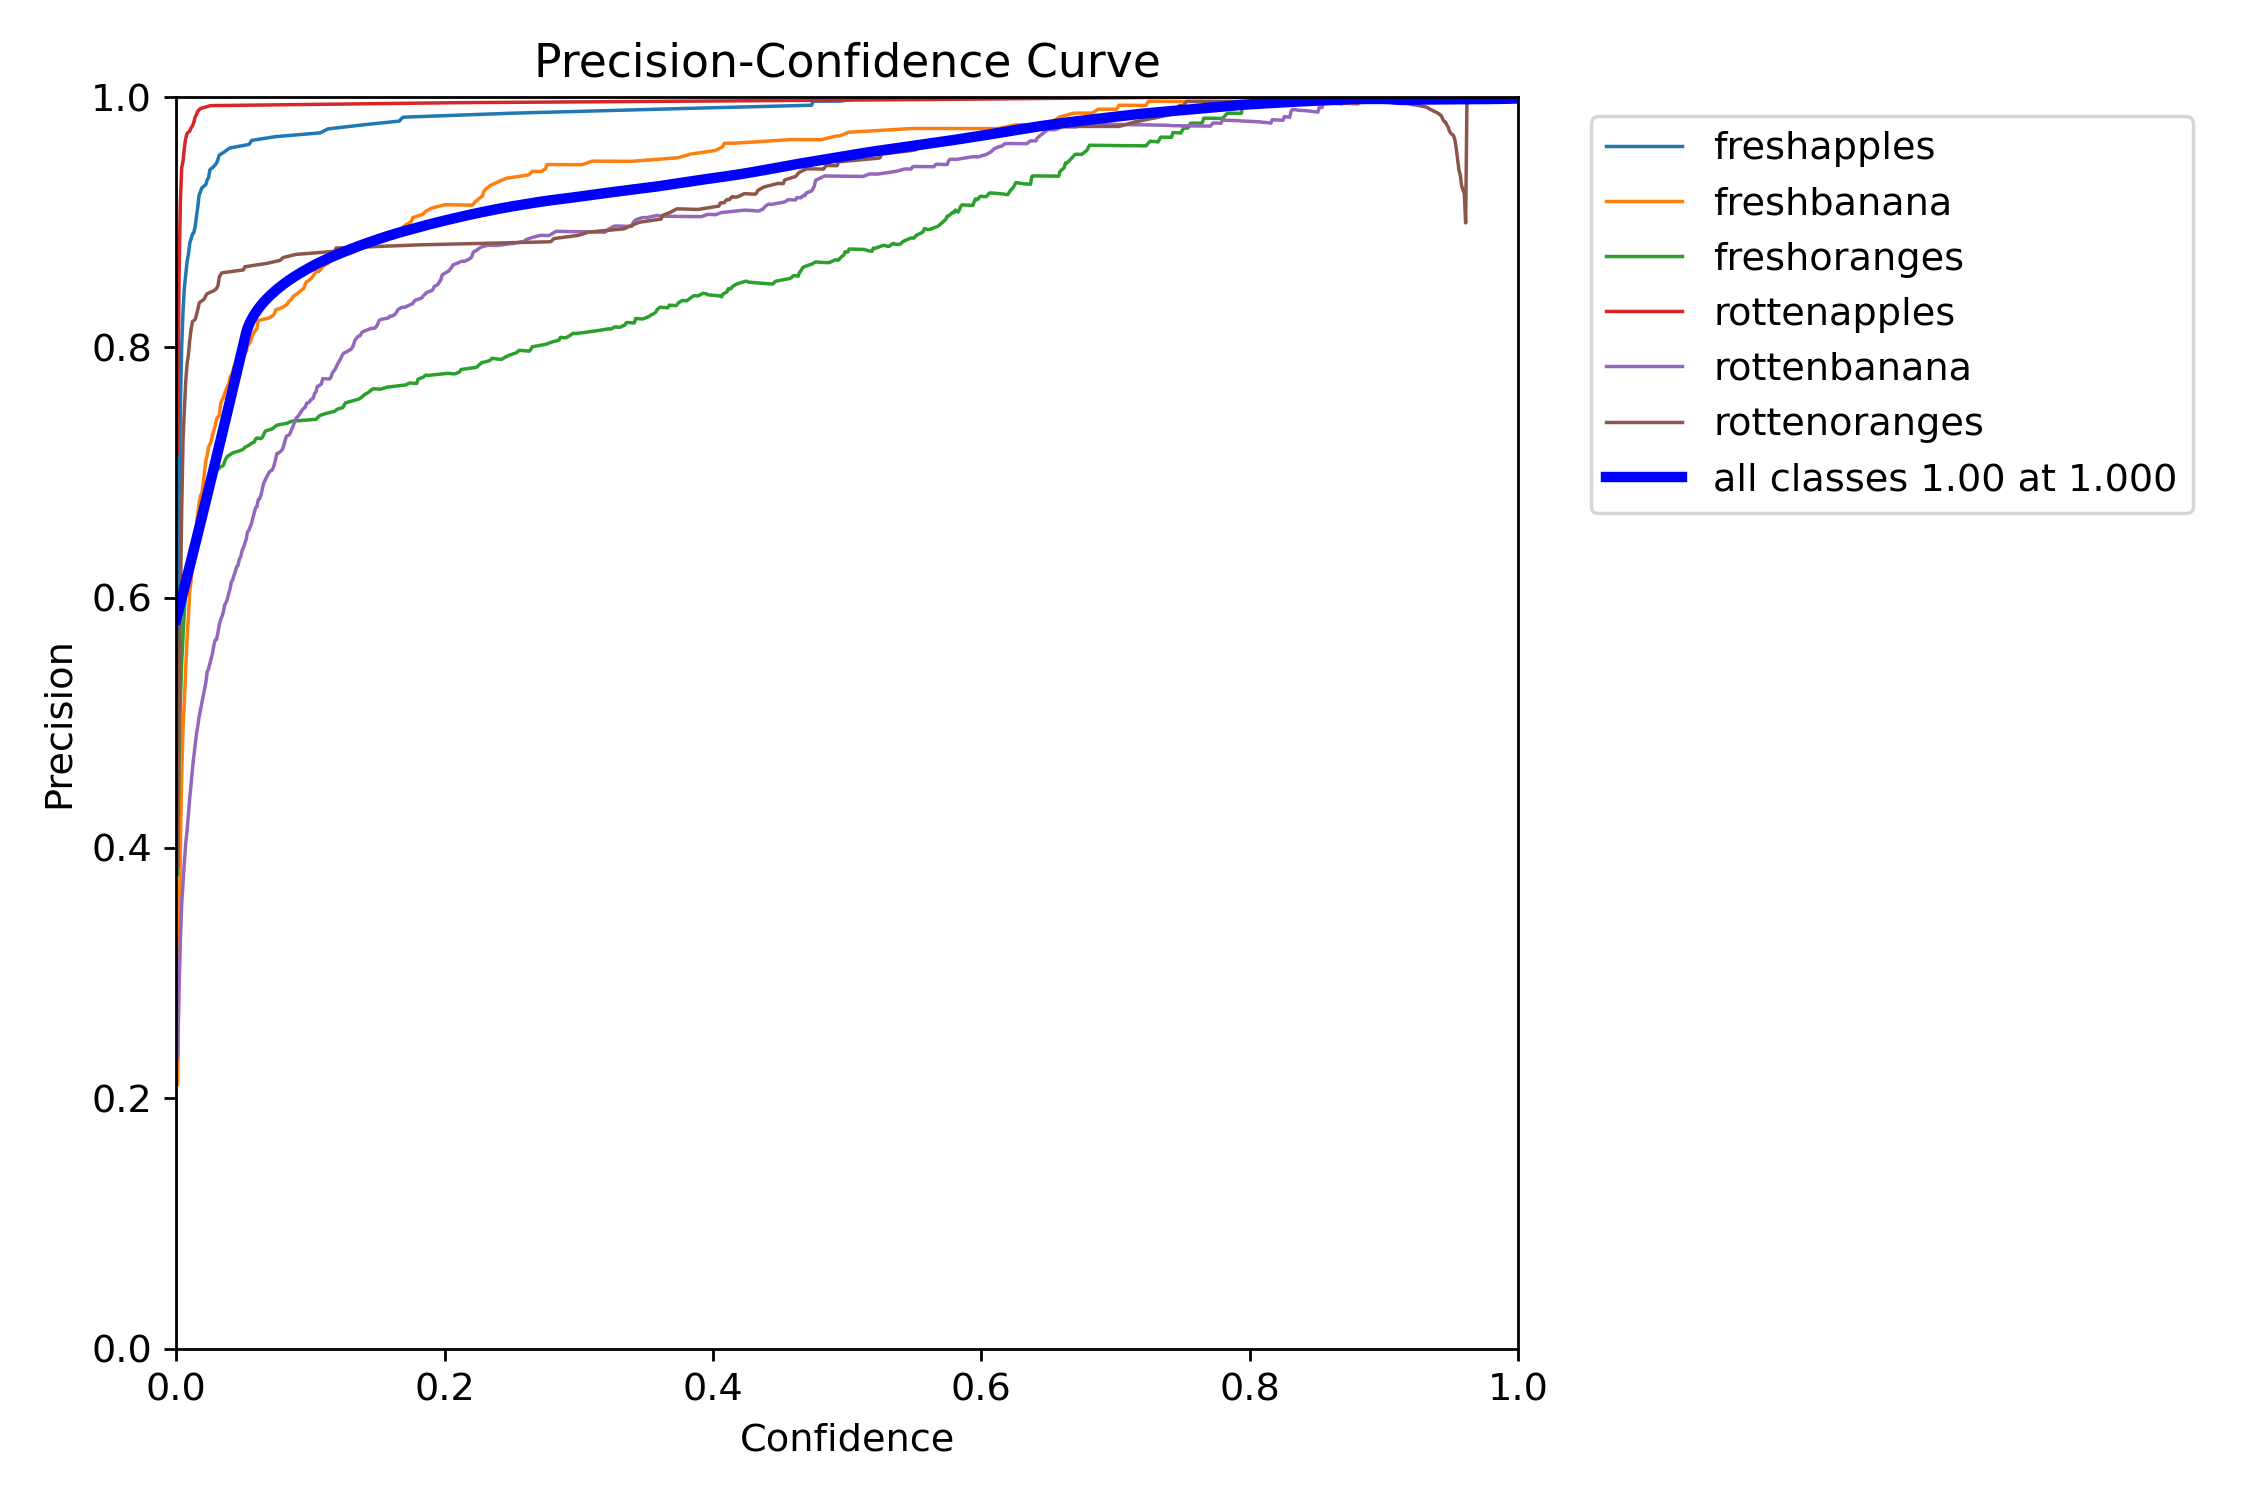

In [16]:
display(Image("/content/runs/detect/train/BoxP_curve.png"))

In [17]:
import shutil
from google.colab import files

shutil.make_archive(
    "/content/yolov8_paper_charts",
    "zip",
    "/content/runs/detect/train"
)

files.download("/content/yolov8_paper_charts.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>